# MSCI India（BM）と MSCI India IMI（ユニバース）のスタイル（Barra GEMLT）

ベンチマークとユニバースがどのようなスタイルを持つかを、Barra GEMLT の 16 のスタイル（リスクインデックス）で確認する。
`03_q5_drawdown_2018_2020` で、等ウェイトの Q5 が負けた主因が「超大型株のアンダーウェイト」という構造的なベットだと分かったので、
その前提となる BM・ユニバース・ユニバース等ウェイトの違いを整理しておく。

比べるポートフォリオ（すべて月末時点のウェイト）:

| 名前 | 中身 |
| --- | --- |
| BM | MSCI India（大型・中型）。ユニバースの浮動株時価総額ウェイトの部分集合 |
| IMI | MSCI India IMI（大型・中型・小型）。浮動株時価総額ウェイト（`univ` のウェイト） |
| IMI 等ウェイト | IMI の全銘柄を等ウェイト。分位分析の等ウェイト Q1〜Q5 の平均に当たる |

**2 つの基準**

- **グローバル基準**: GEMLT はグローバルモデルで、エクスポージャーは世界の推定ユニバース（時価総額加重平均 0、標準偏差 1）に対する値。インド株全体の「世界から見た」スタイルが分かる。
- **インド内基準**: 各月、IMI の中で時価総額加重平均 0・等ウェイト標準偏差 1 に標準化し直した値。IMI（時価総額ウェイト）が 0 になり、BM と等ウェイトの相対的な傾きが分かる。

後半では、GEMLT のファクターリターンによる指数リターンの分解と、IMI 内のクロスセクション回帰で推定した**インド市場内のスタイル・リターン**を見る。

**規約**: 期間 2008-01〜2026-06（月末）。エクスポージャーは月末 $t$、リターンは翌月。ファクター分解は USD 建て（`rtn_usd`、GEMLT のニューメレール）、インド内回帰は INR 建て（`rtn`）。

In [1]:
import matplotlib.pyplot as plt
import japanize_matplotlib  # noqa: F401  日本語ラベル用
import numpy as np
import pandas as pd

from alphaeval import InputStore

pd.set_option("display.width", 260)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

INPUT_ROOT = "../../input/msci_india_imi"
BENCHMARK = "msci_india"
RISK_MODEL = "GEMLT"
START, END = 200801, 202606
PERIODS = {"2008–2012": ("2008", "2012"), "2013–2017": ("2013", "2017"), "2018–2021": ("2018", "2021"), "2022–2026": ("2022", "2026")}
SECTOR_NAMES = {10: "エネルギー", 15: "素材", 20: "資本財", 25: "一般消費財", 30: "生活必需品", 35: "ヘルスケア", 40: "金融", 45: "情報技術", 50: "通信", 55: "公益", 60: "不動産"}
PORT_COLORS = {"BM": "C0", "IMI": "C1", "IMI 等ウェイト": "C2"}

store = InputStore(INPUT_ROOT)
univ = store.universe(START, END)
dates = univ.index
bm = store.benchmark(BENCHMARK, START, END).reindex(index=dates, columns=univ.columns)
W = {
    "BM": bm.div(bm.sum(axis=1), axis=0),
    "IMI": univ.div(univ.sum(axis=1), axis=0),
    "IMI 等ウェイト": univ.notna().astype(float).where(univ.notna()).pipe(lambda x: x.div(x.sum(axis=1), axis=0)),
}
fl = store.factor_list(RISK_MODEL)
sym = dict(zip(fl["id"], fl["symbol"]))
GROUP = dict(zip(fl["id"], fl["group"].map({"Risk Indices": "Style", "Industries": "Industry", "Countries": "Country", "Currencies": "Currency", "Market": "Market"})))
STYLE_IDS = fl.loc[fl["group"] == "Risk Indices", "id"].tolist()
STYLES = [sym[i] for i in STYLE_IDS]
EXP = {t: store.exposure(RISK_MODEL, t) for t in dates}
style_panel = {sym[k]: pd.DataFrame({t: EXP[t][k] for t in dates}).T.reindex(index=dates, columns=univ.columns) for k in STYLE_IDS}
print(f"{len(dates)} か月、スタイル {len(STYLES)} 本: {', '.join(STYLES)}")

222 か月、スタイル 16 本: BETA, BTOP, DIVYILD, EARNQLTY, EARNVAR, EARNYILD, GROWTH, INVSQLTY, LEVERAGE, LIQUIDTY, LTREVRSL, MIDCAP, MOMENTUM, PROFIT, RESVOL, SIZE


## 1. 構成と集中度

銘柄数、BM が IMI の時価総額に占める割合、上位 10 銘柄のウェイト、実効銘柄数（$1/\sum w^2$）、サイズ区分（MSCI の大型・中型・小型）別のウェイト。

,2008–2012,2013–2017,2018–2021,2022–2026
IMI 銘柄数,305.367,279.367,341.146,585.907
BM 銘柄数,64.933,72.200,86.354,136.222
BM の IMI 時価総額シェア,0.839,0.845,0.828,0.799
BM 上位 10 ウェイト,0.534,0.505,0.508,0.403
IMI 上位 10 ウェイト,0.448,0.427,0.421,0.322
BM 実効銘柄数,23.003,26.884,25.931,40.481
IMI 実効銘柄数,32.424,37.865,37.796,62.833
IMI の大型ウェイト,0.730,0.727,0.720,0.661
BM の大型ウェイト,0.869,0.860,0.869,0.827
IMI の中型ウェイト,0.109,0.117,0.108,0.138


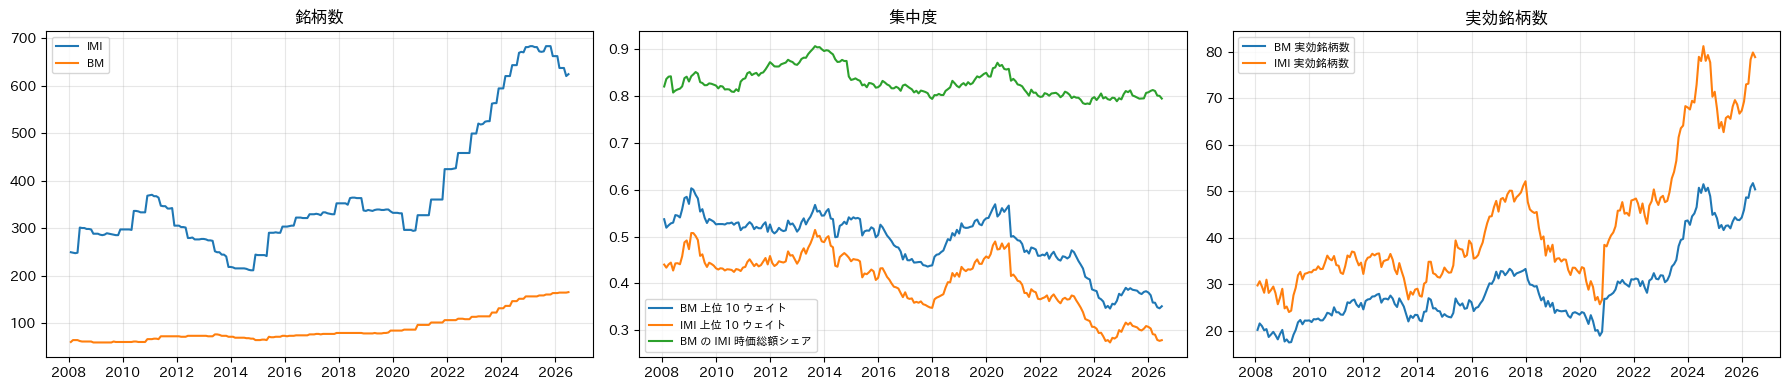

In [2]:
size_cls = store.alpha("attributes/size", START, END).reindex(index=dates, columns=univ.columns)
conc = pd.DataFrame({
    "IMI 銘柄数": univ.notna().sum(axis=1),
    "BM 銘柄数": bm.notna().sum(axis=1),
    "BM の IMI 時価総額シェア": W["IMI"].where(bm.notna()).sum(axis=1),
    "BM 上位 10 ウェイト": W["BM"].apply(lambda r: r.nlargest(10).sum(), axis=1),
    "IMI 上位 10 ウェイト": W["IMI"].apply(lambda r: r.nlargest(10).sum(), axis=1),
    "BM 実効銘柄数": 1 / (W["BM"] ** 2).sum(axis=1),
    "IMI 実効銘柄数": 1 / (W["IMI"] ** 2).sum(axis=1),
})
for k, lab in {1: "大型", 2: "中型", 3: "小型"}.items():
    conc[f"IMI の{lab}ウェイト"] = W["IMI"].where(size_cls == k).sum(axis=1)
    conc[f"BM の{lab}ウェイト"] = W["BM"].where(size_cls == k).sum(axis=1)
display(pd.DataFrame({p: conc.loc[a:b].mean() for p, (a, b) in PERIODS.items()}).round(3))

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(conc.index, conc["IMI 銘柄数"], label="IMI")
axes[0].plot(conc.index, conc["BM 銘柄数"], label="BM")
axes[0].set_title("銘柄数")
for c in ["BM 上位 10 ウェイト", "IMI 上位 10 ウェイト", "BM の IMI 時価総額シェア"]:
    axes[1].plot(conc.index, conc[c], label=c)
axes[1].set_title("集中度")
for c in ["BM 実効銘柄数", "IMI 実効銘柄数"]:
    axes[2].plot(conc.index, conc[c], label=c)
axes[2].set_title("実効銘柄数")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 2. スタイル・エクスポージャー（グローバル基準）

各ポートフォリオのウェイト加重平均エクスポージャー。0 = 世界の時価総額加重平均。

BM                                           IMI                                     IMI 等ウェイト                                    
         2008–2012 2013–2017 2018–2021 2022–2026   全期間 2008–2012 2013–2017 2018–2021 2022–2026   全期間 2008–2012 2013–2017 2018–2021 2022–2026   全期間
BETA         -0.04     -0.58     -0.66     -0.87 -0.52     -0.08     -0.60     -0.69     -0.87 -0.54     -0.22     -0.62     -0.85     -0.88 -0.63
BTOP         -0.10     -0.09     -0.02     -0.01 -0.06     -0.02     -0.04      0.00      0.01 -0.01      0.46      0.34      0.21      0.09  0.29
DIVYILD      -0.09     -0.07     -0.01     -0.00 -0.04     -0.06     -0.09     -0.05     -0.03 -0.06      0.05     -0.12     -0.06     -0.12 -0.06
EARNQLTY     -0.06     -0.10     -0.08      0.00 -0.06     -0.07     -0.09     -0.06     -0.02 -0.06     -0.06      0.04      0.07     -0.10 -0.01
EARNVAR      -0.06     -0.05     -0.08     -0.08 -0.06      0.03      0.02     -0.02     -0.02  0.00      0.47      0.41      0.30      0.26  0.36
EARNYILD     -0.15     -0.06     -0.00      0.01 -0.05     -0.07     -0.05     -0.00     -0.01 -0.03      0.33      0.06      0.14     -0.01  0.13
GROWTH        0.08      0.04      0.01      0.01  0.04      0.08      0.04      0.02      0.00  0.04     -0.02     -0.05      0.03     -0.04 -0.02
INVSQLTY     -0.02     -0.04      0.00     -0.02 -0.02     -0.06     -0.04     -0.01     -0.03 -0.04     -0.27     -0.07     -0.03     -0.03 -0.11
LEVERAGE      0.02      0.03      0.13      0.12  0.07      0.06      0.05      0.11      0.05  0.06      0.28      0.21     -0.02     -0.21  0.08
LIQUIDTY      0.28      0.17      0.15      0.01  0.15      0.26      0.20      0.16      0.12  0.19      0.11      0.26      0.11      0.40  0.22
LTREVRSL     -0.49      0.17      0.14     -0.24 -0.11     -0.42      0.17      0.16     -0.24 -0.09     -0.08      0.27      0.29     -0.22  0.06
MIDCAP       -0.07     -0.09     -0.10     -0.12 -0.09      0.02      0.01      0.03      0.05  0.02      0.10      0.22      0.30      0.38  0.24
MOMENTUM      0.09     -0.14     -0.01      0.04 -0.01      0.05     -0.11     -0.03      0.05 -0.01     -0.37     -0.25     -0.43     -0.08 -0.28
PROFIT        0.03      0.06     -0.08     -0.14 -0.02     -0.04      0.01     -0.08     -0.08 -0.04     -0.31     -0.32     -0.07      0.10 -0.16
RESVOL        0.64      0.77      0.56      0.11  0.53      0.66      0.79      0.61      0.17  0.56      0.79      0.89      0.83      0.43  0.74
SIZE          0.30      0.32      0.40      0.44  0.36     -0.04      0.01      0.06      0.03  0.01     -1.70     -1.50     -1.50     -1.52 -1.56

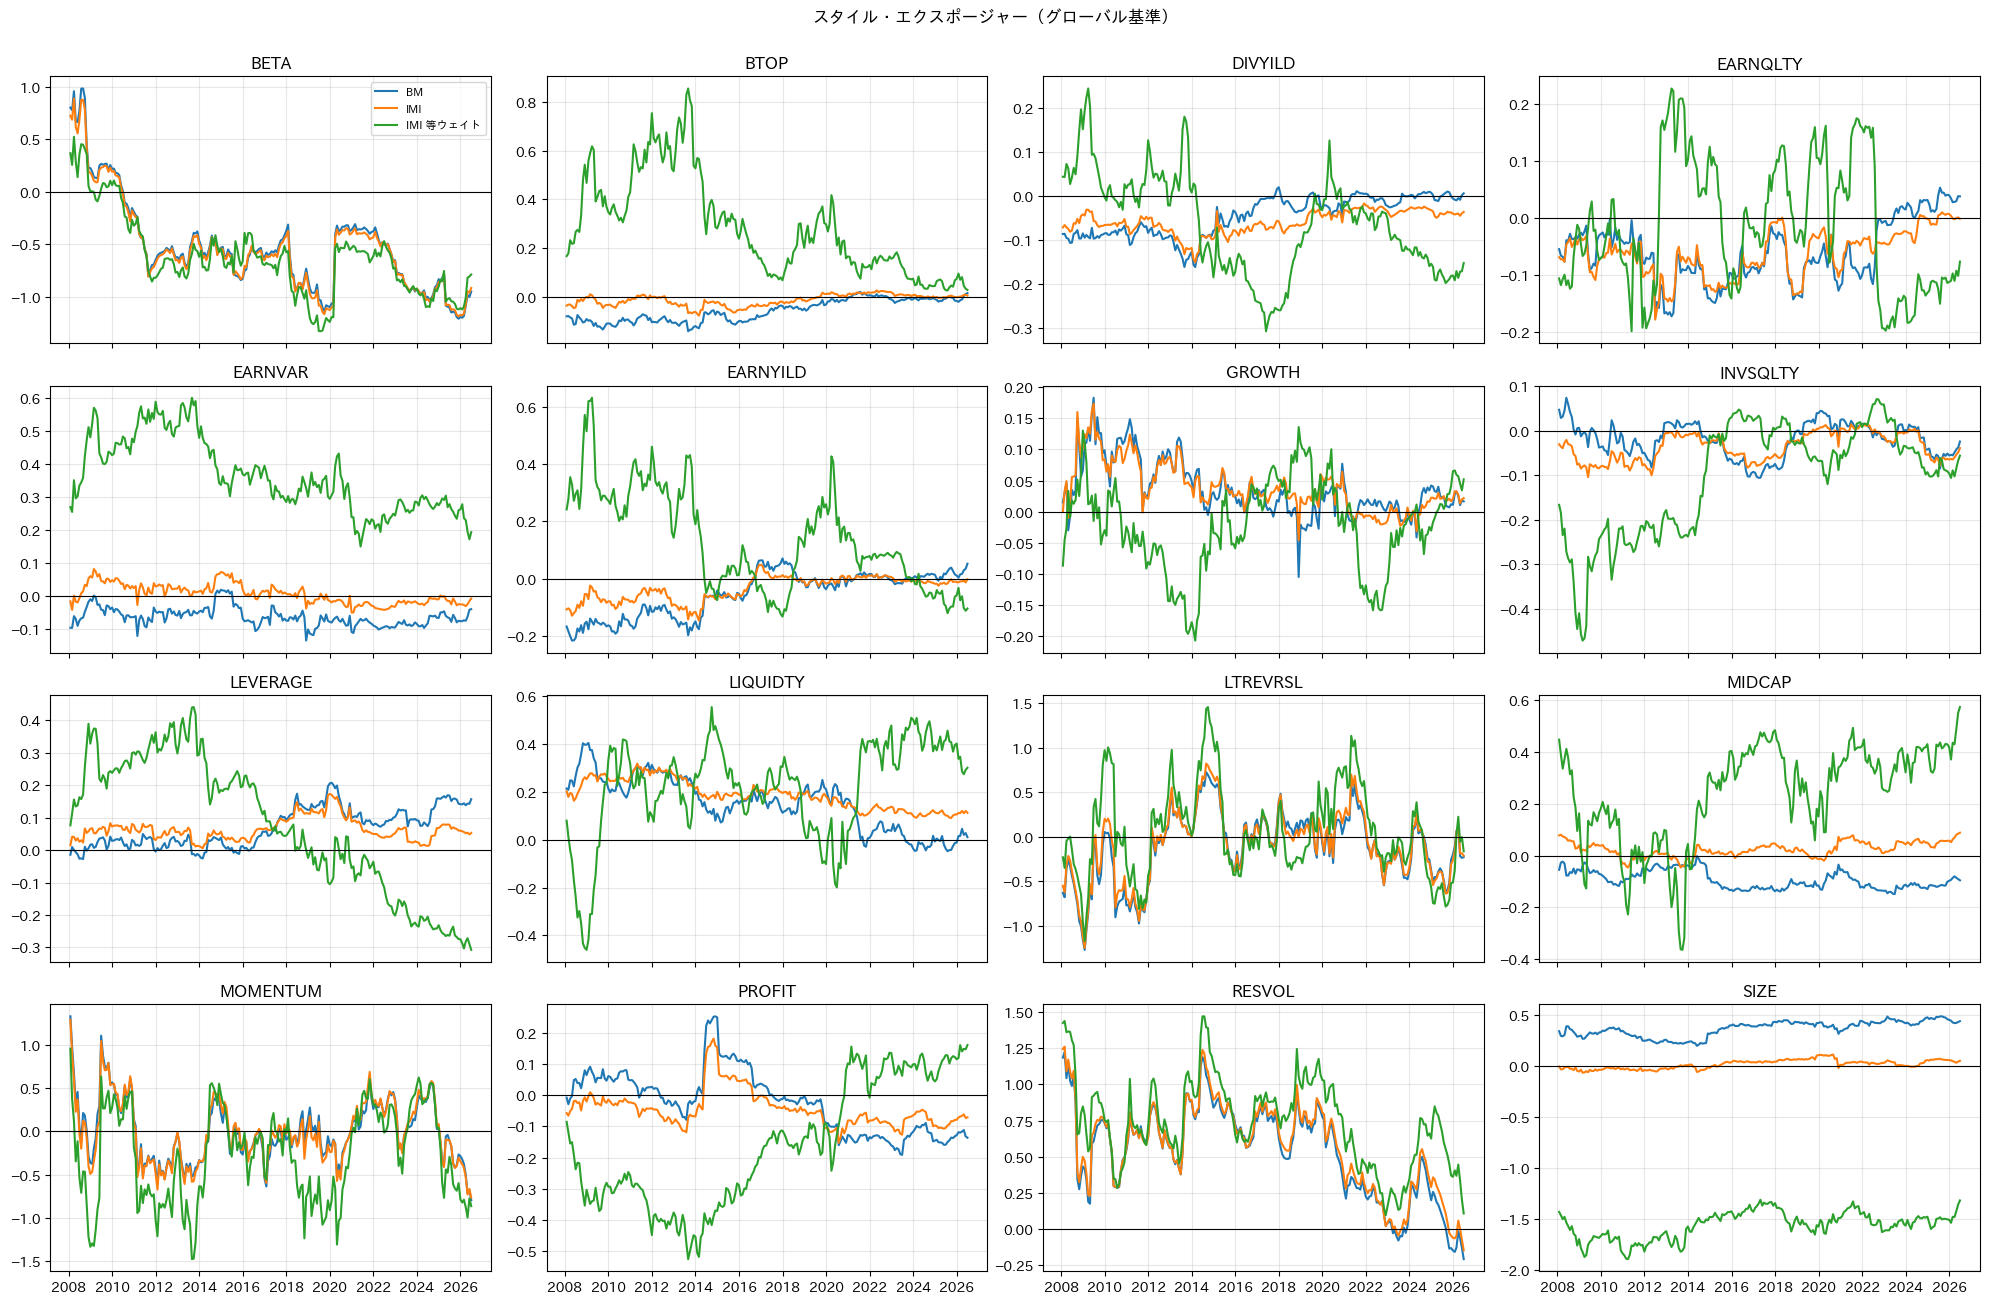

In [3]:
def port_exposure(w: pd.DataFrame, panel: pd.DataFrame) -> pd.Series:
    return (w * panel).sum(axis=1) / w.where(panel.notna()).sum(axis=1)

gexp = {p: pd.DataFrame({s: port_exposure(w, style_panel[s]) for s in STYLES}) for p, w in W.items()}
tbl = pd.concat({p: pd.DataFrame({k: e.loc[a:b].mean() for k, (a, b) in PERIODS.items()}).assign(全期間=e.mean()) for p, e in gexp.items()}, axis=1)
display(tbl.round(2))

fig, axes = plt.subplots(4, 4, figsize=(20, 13), sharex=True)
for ax, s in zip(axes.ravel(), STYLES):
    for p, e in gexp.items():
        ax.plot(e.index, e[s], label=p, color=PORT_COLORS[p])
    ax.axhline(0, color="k", linewidth=0.8)
    ax.set_title(s)
axes[0, 0].legend(fontsize=8)
fig.suptitle("スタイル・エクスポージャー（グローバル基準）", y=1.0)
plt.tight_layout()
plt.show()

## 3. スタイル・エクスポージャー（インド内基準）

各月 IMI 内で `(x − IMI 時価総額加重平均) / IMI 等ウェイト標準偏差` に標準化。IMI = 0。

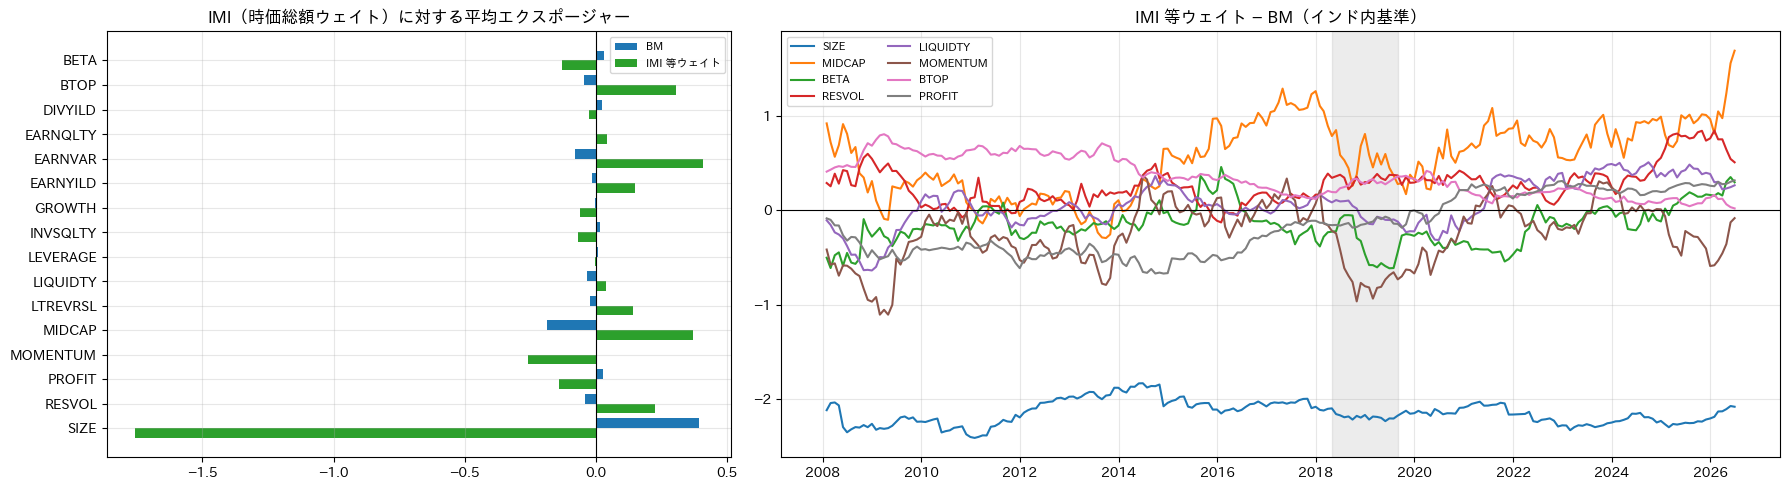

BM                                     IMI 等ウェイト                                     等ウェイト − BM                                    
         2008–2012 2013–2017 2018–2021 2022–2026   全期間 2008–2012 2013–2017 2018–2021 2022–2026   全期間  2008–2012 2013–2017 2018–2021 2022–2026   全期間
BETA          0.04      0.02      0.07     -0.00  0.03     -0.19     -0.04     -0.29     -0.02 -0.13      -0.23     -0.07     -0.36     -0.02 -0.16
BTOP         -0.09     -0.04     -0.02     -0.02 -0.05      0.52      0.33      0.23      0.11  0.31       0.61      0.37      0.26      0.13  0.35
DIVYILD      -0.04      0.04      0.04      0.05  0.02      0.17     -0.09     -0.03     -0.16 -0.02       0.21     -0.13     -0.08     -0.22 -0.05
EARNQLTY      0.01     -0.01     -0.02      0.02  0.00      0.01      0.13      0.12     -0.08  0.04      -0.00      0.13      0.15     -0.11  0.04
EARNVAR      -0.09     -0.08     -0.07     -0.07 -0.08      0.50      0.43      0.35      0.32  0.41       0.60      0.51      0.42      0.39  0.49
EARNYILD     -0.07     -0.00      0.00      0.02 -0.01      0.35      0.08      0.15      0.00  0.15       0.42      0.08      0.15     -0.02  0.16
GROWTH        0.00     -0.00     -0.02      0.01 -0.00     -0.10     -0.09      0.00     -0.04 -0.06      -0.11     -0.08      0.02     -0.05 -0.06
INVSQLTY      0.05     -0.00      0.02      0.01  0.02     -0.20     -0.03     -0.03     -0.00 -0.07      -0.24     -0.02     -0.05     -0.01 -0.09
LEVERAGE     -0.04     -0.02      0.02      0.08  0.01      0.20      0.14     -0.12     -0.29 -0.00       0.24      0.16     -0.14     -0.36 -0.01
LIQUIDTY      0.01     -0.03     -0.01     -0.10 -0.03     -0.11      0.04     -0.03      0.27  0.04      -0.12      0.07     -0.02      0.37  0.07
LTREVRSL     -0.06     -0.00     -0.02      0.00 -0.02      0.32      0.08      0.13      0.02  0.14       0.39      0.08      0.15      0.02  0.17
MIDCAP       -0.12     -0.17     -0.19     -0.28 -0.19      0.13      0.39      0.42      0.57  0.37       0.24      0.56      0.61      0.85  0.56
MOMENTUM      0.04     -0.03      0.02     -0.01  0.00     -0.40     -0.13     -0.37     -0.14 -0.26      -0.44     -0.09     -0.39     -0.13 -0.26
PROFIT        0.08      0.06      0.00     -0.05  0.03     -0.33     -0.37      0.00      0.19 -0.14      -0.41     -0.43      0.00      0.24 -0.17
RESVOL       -0.03     -0.02     -0.05     -0.08 -0.04      0.16      0.14      0.26      0.37  0.23       0.19      0.16      0.31      0.44  0.27
SIZE          0.38      0.35      0.39      0.46  0.39     -1.85     -1.66     -1.75     -1.76 -1.76      -2.23     -2.01     -2.14     -2.23 -2.15

In [4]:
local_panel = {}
for s in STYLES:
    x = style_panel[s].where(univ.notna())
    mu = (W["IMI"] * x).sum(axis=1) / W["IMI"].where(x.notna()).sum(axis=1)
    sd = x.std(axis=1)
    local_panel[s] = x.sub(mu, axis=0).div(sd, axis=0)
lexp = {p: pd.DataFrame({s: port_exposure(w, local_panel[s]) for s in STYLES}) for p, w in W.items() if p != "IMI"}
avg = pd.DataFrame({p: e.mean() for p, e in lexp.items()})
fig, axes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={"width_ratios": [1, 1.6]})
y = np.arange(len(STYLES))
axes[0].barh(y - 0.2, avg["BM"], height=0.4, label="BM", color=PORT_COLORS["BM"])
axes[0].barh(y + 0.2, avg["IMI 等ウェイト"], height=0.4, label="IMI 等ウェイト", color=PORT_COLORS["IMI 等ウェイト"])
axes[0].set_yticks(y, STYLES)
axes[0].invert_yaxis()
axes[0].axvline(0, color="k", linewidth=0.8)
axes[0].set_title("IMI（時価総額ウェイト）に対する平均エクスポージャー")
axes[0].legend(fontsize=8)
diff = lexp["IMI 等ウェイト"] - lexp["BM"]
for s in ["SIZE", "MIDCAP", "BETA", "RESVOL", "LIQUIDTY", "MOMENTUM", "BTOP", "PROFIT"]:
    axes[1].plot(diff.index, diff[s], label=s)
axes[1].axhline(0, color="k", linewidth=0.8)
axes[1].axvspan(pd.Timestamp("2018-04-30"), pd.Timestamp("2019-08-31"), color="grey", alpha=0.15)
axes[1].set_title("IMI 等ウェイト − BM（インド内基準）")
axes[1].legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()
display(pd.concat({p: pd.DataFrame({k: e.loc[a:b].mean() for k, (a, b) in PERIODS.items()}).assign(全期間=e.mean()) for p, e in {**lexp, "等ウェイト − BM": diff}.items()}, axis=1).round(2))

## 4. セクター構成（GICS）

BM                                     IMI                               IMI 等ウェイト                              
      2008–2012 2013–2017 2018–2021 2022–2026 2008–2012 2013–2017 2018–2021 2022–2026 2008–2012 2013–2017 2018–2021 2022–2026
エネルギー     0.163     0.112     0.142     0.106     0.142     0.096     0.119     0.086     0.038     0.030     0.031     0.020
素材        0.096     0.073     0.087     0.086     0.103     0.080     0.097     0.101     0.168     0.144     0.161     0.172
資本財       0.087     0.057     0.042     0.079     0.101     0.076     0.062     0.105     0.169     0.162     0.158     0.195
一般消費財     0.052     0.097     0.090     0.113     0.068     0.112     0.101     0.118     0.149     0.176     0.154     0.157
生活必需品     0.068     0.107     0.105     0.078     0.068     0.098     0.095     0.069     0.061     0.071     0.070     0.060
ヘルスケア     0.042     0.089     0.052     0.053     0.048     0.088     0.061     0.065     0.075     0.092     0.102     0.095
金融        0.260     0.213     0.249     0.267     0.252     0.213     0.240     0.247     0.183     0.185     0.161     0.142
情報技術      0.157     0.194     0.170     0.124     0.145     0.177     0.154     0.114     0.091     0.070     0.062     0.065
通信        0.019     0.030     0.031     0.037     0.018     0.027     0.031     0.036     0.017     0.016     0.032     0.030
公益        0.056     0.028     0.029     0.046     0.055     0.031     0.033     0.042     0.050     0.048     0.043     0.033
不動産       0.000     0.000     0.002     0.011     0.000     0.001     0.007     0.016     0.000     0.005     0.027     0.031

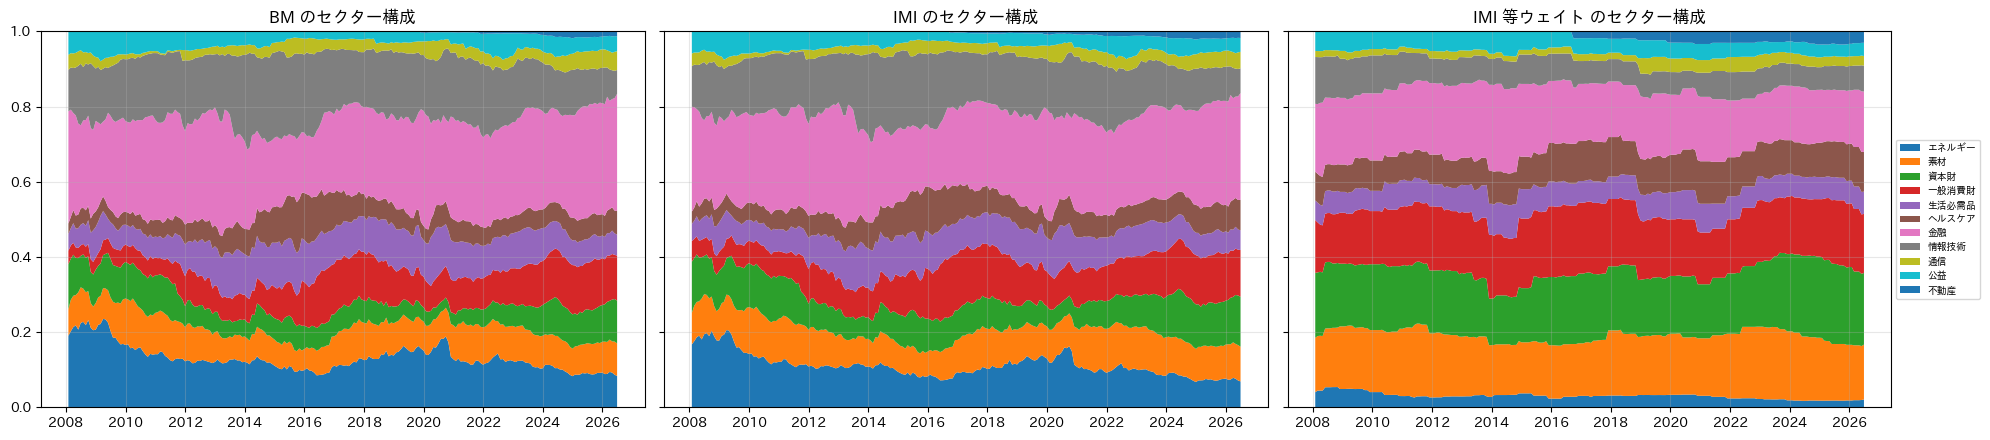

In [5]:
sector = (store.alpha("attributes/gics", START, END).reindex(index=dates, columns=univ.columns) // 1_000_000)
sec_w = {p: pd.DataFrame({SECTOR_NAMES[k]: w.where(sector == k).sum(axis=1) for k in SECTOR_NAMES}) for p, w in W.items()}
display(pd.concat({p: pd.DataFrame({k: v.loc[a:b].mean() for k, (a, b) in PERIODS.items()}) for p, v in sec_w.items()}, axis=1).round(3))
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5), sharey=True)
for ax, (p, v) in zip(axes, sec_w.items()):
    ax.stackplot(v.index, v.T.to_numpy(), labels=v.columns)
    ax.set_title(f"{p} のセクター構成")
    ax.set_ylim(0, 1)
axes[-1].legend(fontsize=7, loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.tight_layout()
plt.show()

## 5. GEMLT ファクターリターンによるリターン分解（USD）

ポートフォリオのエクスポージャー（月末 $t$）× 翌月のファクターリターンをグループ別に合計し、実際のリターンとの差を固有とする。

In [6]:
fr = store.factor_return(RISK_MODEL)
r_usd = store.returns(RISK_MODEL, "rtn_usd", START, 202607)
dec = {p: {} for p in W}
style_contrib = {p: {} for p in W}
for t in dates:
    pos = fr.index.searchsorted(t, side="right")
    if pos >= len(fr.index) or fr.index[pos] not in r_usd.index:
        continue
    nxt = fr.index[pos]
    X = EXP[t]
    f = fr.loc[nxt].reindex(X.columns).fillna(0)
    for p, w in W.items():
        wt = w.loc[t].reindex(X.index).fillna(0)
        wt = wt / wt.sum()
        xp = X.T.fillna(0) @ wt
        c = xp * f
        g = c.groupby(pd.Series(c.index.map(GROUP), index=c.index)).sum().to_dict()
        g["実リターン"] = float((wt * r_usd.loc[nxt].reindex(wt.index)).sum())
        g["固有"] = g["実リターン"] - float(c.sum())
        dec[p][nxt] = g
        style_contrib[p][nxt] = c.reindex(STYLE_IDS).rename(index=sym)
dec = {p: pd.DataFrame(v).T for p, v in dec.items()}
style_contrib = {p: pd.DataFrame(v).T for p, v in style_contrib.items()}
cols = ["Market", "Country", "Currency", "Style", "Industry", "固有", "実リターン"]
for p in W:
    print(f"{p}: 年次合計（USD、月次の単純和）")
    d = dec[p][cols]
    display(d.groupby(d.index.year).sum().loc[2009:2025].round(3).T)
act = {"IMI − BM": dec["IMI"][cols] - dec["BM"][cols], "IMI 等ウェイト − BM": dec["IMI 等ウェイト"][cols] - dec["BM"][cols]}
for k, d in act.items():
    print(f"{k}: 年次合計")
    display(d.groupby(d.index.year).sum().loc[2009:2025].round(3).T)

BM: 年次合計（USD、月次の単純和）


,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Market,0.311,0.133,-0.088,0.156,0.227,0.086,0.016,0.087,0.175,-0.089,0.205,0.148,0.161,-0.156,0.130,0.095,0.148
Country,0.269,-0.084,-0.235,0.107,-0.259,0.201,-0.027,-0.064,0.133,-0.047,-0.128,0.082,0.142,0.143,0.172,0.008,-0.050
Currency,0.101,0.098,-0.079,0.064,-0.025,0.067,0.031,0.043,0.117,-0.034,0.025,0.021,0.021,-0.074,0.015,-0.006,-0.024
Style,0.015,-0.009,-0.045,-0.043,-0.033,-0.032,-0.044,-0.026,-0.024,-0.000,-0.068,0.018,-0.002,-0.004,-0.054,0.034,-0.075
Industry,0.007,-0.001,-0.005,0.014,0.011,-0.007,0.025,0.005,0.007,0.005,-0.009,-0.005,-0.013,0.007,0.003,0.006,-0.026
固有,0.098,0.083,0.036,-0.023,0.073,-0.088,-0.051,-0.040,-0.067,0.109,0.059,-0.045,-0.060,0.023,-0.059,-0.010,0.081
実リターン,0.801,0.221,-0.417,0.275,-0.006,0.227,-0.051,0.005,0.340,-0.056,0.083,0.220,0.250,-0.062,0.206,0.126,0.054


IMI: 年次合計（USD、月次の単純和）


,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Market,0.311,0.133,-0.088,0.156,0.227,0.086,0.016,0.087,0.175,-0.089,0.205,0.148,0.161,-0.156,0.130,0.095,0.148
Country,0.274,-0.086,-0.242,0.110,-0.267,0.208,-0.029,-0.068,0.140,-0.050,-0.136,0.084,0.149,0.150,0.181,0.007,-0.053
Currency,0.101,0.098,-0.079,0.064,-0.025,0.067,0.031,0.043,0.117,-0.034,0.025,0.021,0.021,-0.074,0.015,-0.006,-0.024
Style,0.058,0.004,-0.058,-0.041,-0.029,-0.033,-0.037,-0.026,-0.017,-0.012,-0.077,0.007,0.001,-0.015,-0.056,0.035,-0.081
Industry,0.007,-0.001,-0.005,0.015,0.009,-0.005,0.020,0.004,0.006,0.002,-0.008,-0.004,-0.011,0.003,0.001,0.002,-0.025
固有,0.078,0.074,0.034,-0.015,0.065,-0.064,-0.036,-0.029,-0.045,0.085,0.054,-0.024,-0.039,0.019,-0.031,0.012,0.068
実リターン,0.829,0.222,-0.437,0.289,-0.019,0.258,-0.035,0.011,0.376,-0.098,0.063,0.233,0.282,-0.073,0.240,0.145,0.033


IMI 等ウェイト: 年次合計（USD、月次の単純和）


,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Market,0.311,0.133,-0.088,0.156,0.227,0.086,0.016,0.087,0.175,-0.089,0.205,0.148,0.161,-0.156,0.130,0.095,0.148
Country,0.303,-0.095,-0.279,0.136,-0.320,0.256,-0.037,-0.081,0.170,-0.055,-0.167,0.099,0.175,0.181,0.216,0.008,-0.064
Currency,0.101,0.098,-0.079,0.064,-0.025,0.067,0.031,0.043,0.117,-0.034,0.025,0.021,0.021,-0.074,0.015,-0.006,-0.024
Style,0.314,0.052,-0.144,-0.033,-0.009,-0.055,-0.028,-0.012,-0.013,-0.071,-0.128,-0.065,0.008,-0.049,-0.069,0.035,-0.113
Industry,0.014,0.005,-0.004,0.016,-0.005,0.001,-0.008,0.003,0.006,-0.010,-0.005,0.007,-0.001,-0.002,-0.010,-0.015,-0.024
固有,-0.022,0.025,0.055,0.027,0.010,0.054,0.008,0.026,0.035,-0.012,0.011,0.116,0.014,0.004,0.082,0.092,0.042
実リターン,1.020,0.219,-0.539,0.367,-0.122,0.409,-0.017,0.067,0.489,-0.272,-0.060,0.327,0.378,-0.096,0.363,0.209,-0.036


IMI − BM: 年次合計


,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Market,-0.000,-0.000,-0.000,0.000,-0.000,0.000,0.000,0.000,-0.000,0.000,0.000,0.000,-0.000,-0.000,0.000,-0.000,-0.000
Country,0.005,-0.002,-0.007,0.003,-0.008,0.006,-0.002,-0.004,0.008,-0.003,-0.008,0.002,0.007,0.008,0.009,-0.000,-0.004
Currency,-0.000,-0.000,-0.000,0.000,0.000,-0.000,0.000,0.000,-0.000,0.000,-0.000,0.000,-0.000,0.000,0.000,-0.000,0.000
Style,0.043,0.012,-0.013,0.002,0.004,-0.002,0.007,0.001,0.006,-0.012,-0.009,-0.011,0.003,-0.012,-0.001,0.002,-0.006
Industry,-0.000,0.000,0.000,0.001,-0.001,0.001,-0.005,-0.001,-0.000,-0.003,0.001,0.001,0.002,-0.003,-0.002,-0.004,0.001
固有,-0.020,-0.009,-0.001,0.008,-0.007,0.024,0.015,0.011,0.023,-0.024,-0.005,0.020,0.021,-0.004,0.028,0.022,-0.013
実リターン,0.027,0.001,-0.021,0.014,-0.013,0.030,0.015,0.007,0.037,-0.042,-0.020,0.013,0.033,-0.012,0.034,0.020,-0.021


IMI 等ウェイト − BM: 年次合計


,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Market,0.000,-0.000,-0.000,-0.000,0.000,0.000,-0.000,-0.000,-0.000,-0.000,0.000,-0.000,0.000,-0.000,-0.000,-0.000,0.000
Country,0.033,-0.011,-0.044,0.030,-0.062,0.055,-0.010,-0.018,0.037,-0.008,-0.039,0.017,0.033,0.038,0.044,0.001,-0.015
Currency,0.000,-0.000,0.000,-0.000,-0.000,-0.000,-0.000,-0.000,-0.000,0.000,0.000,-0.000,0.000,0.000,-0.000,0.000,0.000
Style,0.299,0.061,-0.099,0.010,0.024,-0.024,0.017,0.015,0.011,-0.070,-0.060,-0.082,0.010,-0.045,-0.015,0.002,-0.038
Industry,0.007,0.007,0.002,0.002,-0.015,0.008,-0.033,-0.002,-0.001,-0.016,0.005,0.012,0.012,-0.009,-0.014,-0.021,0.001
固有,-0.120,-0.058,0.019,0.050,-0.063,0.142,0.059,0.066,0.103,-0.121,-0.048,0.160,0.074,-0.019,0.141,0.102,-0.039
実リターン,0.219,-0.002,-0.122,0.091,-0.116,0.181,0.034,0.062,0.149,-0.215,-0.143,0.107,0.128,-0.034,0.157,0.083,-0.090


### 5.1 等ウェイト − BM のスタイル別寄与（年次）

等ウェイトのポートフォリオ（分位分析の Q1〜Q5 の平均）が BM に対してどのスタイルで勝ち負けしたか。

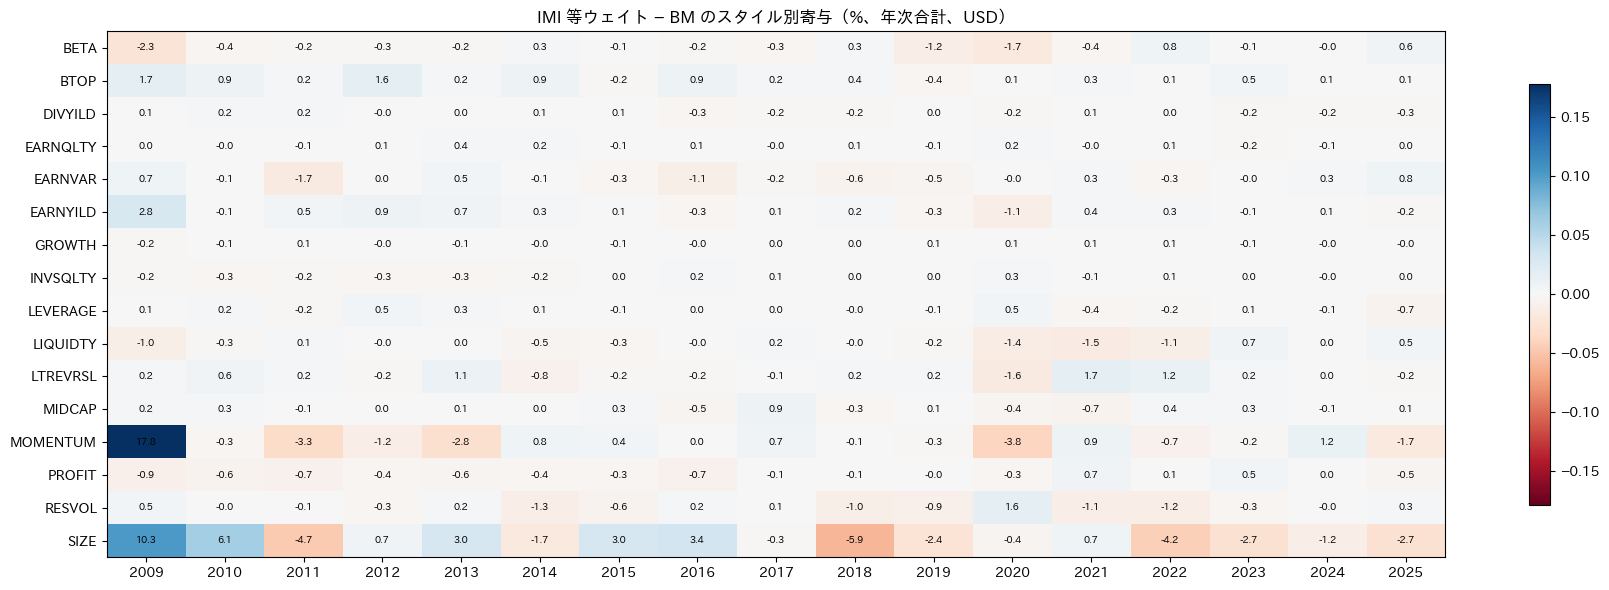

In [7]:
sc = style_contrib["IMI 等ウェイト"] - style_contrib["BM"]
yr = sc.groupby(sc.index.year).sum().loc[2009:2025]
fig, ax = plt.subplots(figsize=(18, 6))
v = yr.T.to_numpy()
lim = np.nanmax(np.abs(v))
im = ax.imshow(v, cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
ax.set_yticks(range(len(yr.columns)), yr.columns)
ax.set_xticks(range(len(yr.index)), yr.index)
for i in range(v.shape[0]):
    for j in range(v.shape[1]):
        ax.text(j, i, f"{v[i, j] * 100:.1f}", ha="center", va="center", fontsize=7)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("IMI 等ウェイト − BM のスタイル別寄与（%、年次合計、USD）")
plt.tight_layout()
plt.show()

## 6. インド市場内のスタイル・リターン（クロスセクション回帰）

GEMLT のファクターリターンは世界全体で推定されたもので、インドの中でどのスタイルが報われたかとは一致しない。
各月、IMI の銘柄について翌月リターン（INR）を、インド内基準のスタイル 16 本 + GICS セクターダミーに回帰する（重み = 時価総額の平方根、WLS）。
係数は「他のスタイルとセクターを一定にして、そのスタイルが 1 標準偏差高いときの翌月リターン」。

,年率,t 値,2008–2012 年率,2013–2017 年率,2018–2021 年率,2022–2026 年率,IMI 等ウェイト − BM（インド内基準、平均）,寄与の目安（年率）
BETA,0.015,1.270,0.012,0.019,0.007,0.021,-0.164,-0.002
BTOP,0.006,0.529,0.027,-0.040,0.025,0.019,0.352,0.002
DIVYILD,0.011,1.399,0.028,0.018,-0.035,0.025,-0.048,-0.001
EARNQLTY,0.016,2.548,0.041,-0.001,0.015,0.007,0.041,0.001
EARNVAR,-0.009,-1.212,-0.010,-0.016,-0.018,0.009,0.486,-0.004
EARNYILD,-0.002,-0.224,-0.010,0.026,-0.035,0.004,0.163,-0.000
GROWTH,0.007,1.176,-0.001,0.019,0.005,0.006,-0.059,-0.000
INVSQLTY,0.024,3.806,0.040,0.017,0.024,0.015,-0.085,-0.002
LEVERAGE,0.018,2.406,0.007,0.037,0.010,0.017,-0.010,-0.000
LIQUIDTY,-0.018,-1.520,-0.019,-0.012,-0.029,-0.012,0.072,-0.001


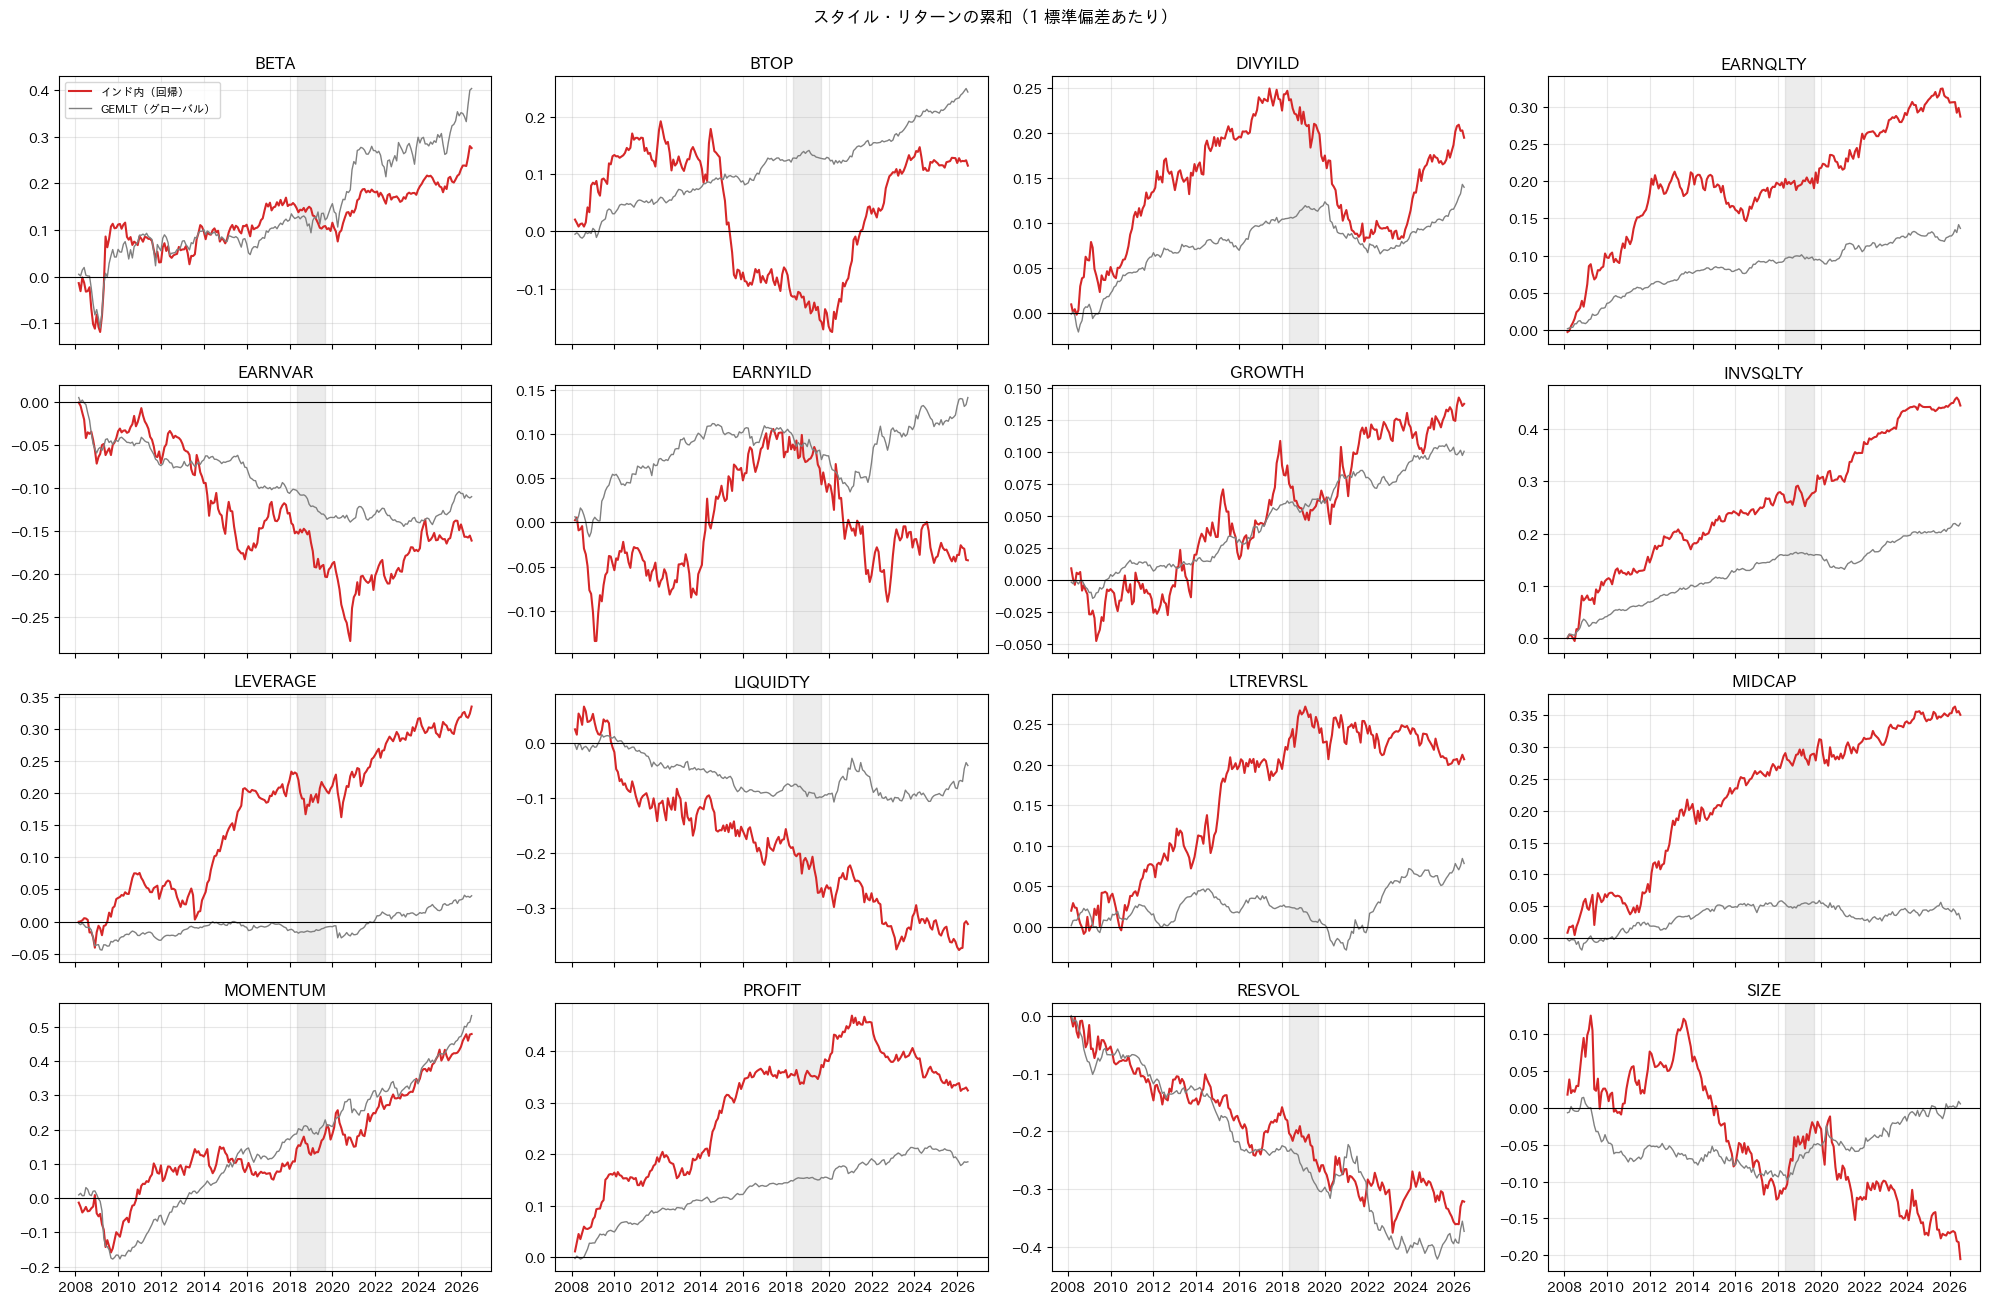

In [8]:
r_inr = store.returns(RISK_MODEL, "rtn", START, 202607)
coefs = {}
for i, t in enumerate(dates[:-1]):
    nxt = dates[i + 1]
    if nxt not in r_inr.index:
        continue
    Z = pd.DataFrame({s: local_panel[s].loc[t] for s in STYLES})
    sec = sector.loc[t]
    y = r_inr.loc[nxt].reindex(Z.index)
    w = univ.loc[t]
    ok = Z.notna().all(axis=1) & sec.notna() & y.notna() & w.notna()
    if ok.sum() < 60:
        continue
    D = pd.get_dummies(sec[ok].astype(int), dtype=float)
    A = pd.concat([Z[ok], D], axis=1).to_numpy()
    sw = np.sqrt(np.sqrt(w[ok].to_numpy()))
    b = np.linalg.lstsq(A * sw[:, None], y[ok].to_numpy() * sw, rcond=None)[0]
    coefs[nxt] = pd.Series(b[: len(STYLES)], index=STYLES)
local_ret = pd.DataFrame(coefs).T
summ = pd.DataFrame({"年率": local_ret.mean() * 12, "t 値": local_ret.mean() / local_ret.std() * np.sqrt(len(local_ret))})
for k, (a, b) in PERIODS.items():
    summ[f"{k} 年率"] = local_ret.loc[a:b].mean() * 12
summ["IMI 等ウェイト − BM（インド内基準、平均）"] = diff.mean()
summ["寄与の目安（年率）"] = summ["年率"] * summ["IMI 等ウェイト − BM（インド内基準、平均）"]
display(summ.round(3))

gfr = fr.reindex(columns=STYLE_IDS).rename(columns=sym).loc[local_ret.index.min():local_ret.index.max()]
fig, axes = plt.subplots(4, 4, figsize=(20, 13), sharex=True)
for ax, s in zip(axes.ravel(), STYLES):
    ax.plot(local_ret.index, local_ret[s].cumsum(), label="インド内（回帰）", color="C3")
    ax.plot(gfr.index, gfr[s].cumsum(), label="GEMLT（グローバル）", color="grey", linewidth=1)
    ax.axhline(0, color="k", linewidth=0.8)
    ax.axvspan(pd.Timestamp("2018-04-30"), pd.Timestamp("2019-08-31"), color="grey", alpha=0.15)
    ax.set_title(s)
axes[0, 0].legend(fontsize=8)
fig.suptitle("スタイル・リターンの累和（1 標準偏差あたり）", y=1.0)
plt.tight_layout()
plt.show()

## 所見

**1. 構成**: BM は IMI の大型・中型部分で、IMI 時価総額の 80〜84% を占める。銘柄数は BM 65 → 136、IMI 305 → 586 と増えた。
BM の上位 10 銘柄ウェイトは 53%（2008〜2012）→ 40%（2022〜2026）、実効銘柄数は 23 → 40 で、集中は近年かなり緩んだ。IMI の小型株ウェイトは 16〜20%。

**2. 世界から見たインド株（グローバル基準）**: BM は低ベータ（BETA −0.52、2022 年以降 −0.87）、高い残差ボラ（RESVOL +0.53、近年は +0.1 まで低下）、
やや割高・低配当（BTOP・EARNYILD・DIVYILD がわずかにマイナス）。SIZE は BM +0.36（インドの超大型株は世界でも大きい側）、IMI ほぼ 0、IMI 等ウェイト −1.56。
BM と IMI（時価総額ウェイト）は SIZE（+0.35）と MIDCAP（−0.11）以外ほぼ同じスタイル。

**3. 等ウェイトの構造的な傾き（インド内基準、IMI 等ウェイト − BM、全期間平均）**

| SIZE | MIDCAP | EARNVAR | BTOP | RESVOL | MOMENTUM | PROFIT | LTREVRSL | EARNYILD | BETA |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| −2.15 | +0.56 | +0.49 | +0.35 | +0.27 | −0.26 | −0.17 | +0.17 | +0.16 | −0.16 |

等ウェイトのポートフォリオ（分位分析の Q1〜Q5 の平均）は、BM に対して「小型・中型、割安、利益が不安定、高ボラ、低モメンタム、低収益性」に傾く。
時期で変わる部分もあり、割安の傾き（BTOP）は 0.61 → 0.13 に縮小し、収益性は 2022 年以降プラス（+0.24）、レバレッジはマイナス（−0.36）に転じ、MIDCAP は 0.24 → 0.85 に強まった。
セクターでは資本財・素材・一般消費財が多く、金融・情報技術・エネルギーが少ない。`03_q5_drawdown_2018_2020` で負けたセクター（資本財、情報技術）と一致する。

**4. 等ウェイト − BM の差の大半は GEMLT の「固有」に入る**: 等ウェイト − BM は年 ±15〜20% の振れ（2014 年 +18%、2017 年 +15%、2018 年 −22%、2019 年 −14%、2023 年 +16%）があるが、
スタイルで説明できるのは一部。2018 年はスタイル −7.0%（うち SIZE −5.9%）に対し固有 −12.1%、2020 年はスタイル −8.2% に対し固有 +16.0%。
GEMLT のグローバルな SIZE ファクターはインドの中小型株サイクルを捉えきれておらず、その分が固有リターンに入っている。
最適化（GEMLT のリスクモデル）では中小型への傾きのリスクが過小評価される可能性があり、bax で実現 TE が推定 TE の 1.2〜1.3 倍だったことと整合する。

**5. インド市場内のスタイル・リターン（1 標準偏差あたり、年率、2008〜2026）**

| スタイル | 年率 | t 値 | 備考 |
| --- | --- | --- | --- |
| MOMENTUM | +2.6% | 2.0 | 近年強まる（2018〜2021 +4.0%、2022〜2026 +5.1%） |
| INVSQLTY（投資の質 = 低い資産成長） | +2.4% | 3.8 | 全期間で安定 |
| MIDCAP | +1.9% | 2.5 | 中型株プレミアム |
| LEVERAGE | +1.8% | 2.4 | |
| PROFIT | +1.8% | 2.4 | 2022 年以降はマイナス（−2.9%） |
| EARNQLTY（利益の質） | +1.6% | 2.5 | |
| RESVOL | −1.7% | −1.7 | 低ボラが報われる |
| LIQUIDTY | −1.8% | −1.5 | 売買の少ない銘柄が報われる |
| SIZE | −1.1% | −1.0 | MIDCAP を一定にすると小型が有利。ただし不安定 |
| BTOP | +0.6% | 0.5 | 2014〜2019 に大きく負け、2020〜2022 に回復 |

2018〜2019 年はバリュー系（BTOP、DIVYILD、EARNYILD、長期リバーサル）が大きく負け、大型・収益性が勝った。

**含意**

- **評価**: 等ウェイト − BM の構造的なベットは年 ±15〜20% 振れるので、素材の比較では EW ユニバース比や SIZE・MIDCAP の中立化で除いて見る。
- **composite の再構築**: インド内で安定して報われたのはモメンタム、投資の質（低い資産成長）、利益の質、中型株。
  利益の質は `core` の `acc_bs`（負のアクルーアル）が正の IC を持ったことと、投資の質は comp_ew のスリーブ D（−資産成長）と整合する。
  ただし素の `ta_grw` の IC は弱かった（t 2.2）ので、他のスタイルを一定にした純粋な効果との差は確認が要る。
- **リスクモデル**: GEMLT ではインドの中小型サイクルが固有リスクに入る。中小型に傾くポートフォリオの TE は推定より大きくなりやすい。